# Three clusters the NFIP claims do form

**DSC 411/511** · Venkat Repaka, Ritik Gaire

Clustering on flood zone, elevation, and construction together does not separate risk profiles (see `05_rq3_check.ipynb`). Three simpler fits do separate. This notebook draws them on the same 20,000-claim sample (seed 42), after dropping claims with no recorded foundation.

1. **Regions** from latitude and longitude.
2. **Zone and foundation pairs.**
3. **Mobile homes** against every other claim.

## 0. Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)

FOUNDATION = {
    '1': 'slab', '2': 'basement', '3': 'crawlspace',
    '4': 'piles', '5': 'piers', '6': 'walls',
}
OLD_TO_NEW = {1: 11, 2: 12, 3: 13, 4: 18, 6: 18}

work = pd.read_parquet('outputs/nfip_claims_simple_clean.parquet')
with open('outputs/simple_feature_lists.json') as f:
    FL = json.load(f)

w3 = work[work['foundationType'] != '0'].copy()
w3['occupancyType'] = w3['occupancyType'].replace(OLD_TO_NEW)
s3 = w3.sample(20000, random_state=SEED).copy()
print(f'Sample: {len(s3):,} claims with a recorded foundation')
print(f"high_severity cutoff: ${work.loc[work['high_severity'] == 1, 'buildingDamageAmount'].min():,.0f}")

Sample: 20,000 claims with a recorded foundation
high_severity cutoff: $106,127


## 1. Regions from latitude and longitude

K-means with k = 4 on the two coordinates. The silhouette on this sample is about 0.68. Names come from the median location and the Florida share, not from a hand-labeled list of states.

Silhouette: 0.682
                       claims  high_severity_share  latitude  longitude
region                                                                 
Florida                 11699                0.306      27.4      -82.2
Northeast                3994                0.084      40.6      -75.5
Gulf, outside Florida    3704                0.089      30.2      -90.5
West                      603                0.114      38.0     -121.7


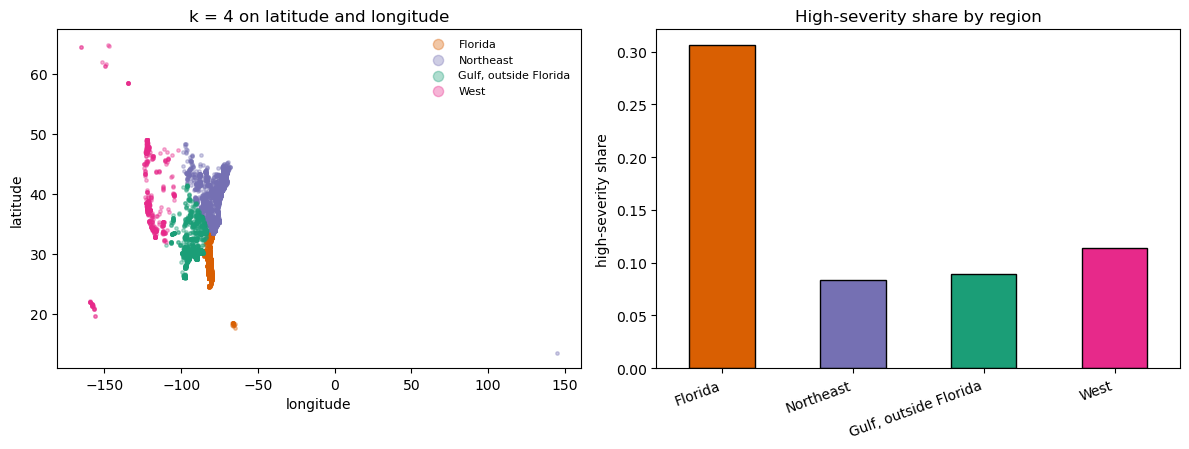

In [2]:
places = s3[['latitude', 'longitude']]
Xp = StandardScaler().fit_transform(places)
geo_labels = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(Xp).labels_
s3['region_id'] = geo_labels
print(f"Silhouette: {silhouette_score(Xp, geo_labels, sample_size=5000, random_state=SEED):.3f}")

regions = s3.groupby('region_id').agg(
    claims=('region_id', 'size'),
    high_severity_share=('high_severity', 'mean'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
    latitude=('latitude', 'median'),
    longitude=('longitude', 'median'),
)

def region_name(row):
    if row['florida_share'] >= 0.8:
        return 'Florida'
    if row['longitude'] < -100:
        return 'West'
    if row['latitude'] >= 35:
        return 'Northeast'
    return 'Gulf, outside Florida'

regions['region'] = regions.apply(region_name, axis=1)
s3['region'] = s3['region_id'].map(regions['region'])
regions = regions.set_index('region').drop(columns='florida_share')
regions = regions.reindex(['Florida', 'Northeast', 'Gulf, outside Florida', 'West'])
print(regions.round(3))

colors = {
    'Florida': '#d95f02',
    'Northeast': '#7570b3',
    'Gulf, outside Florida': '#1b9e77',
    'West': '#e7298a',
}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for name, color in colors.items():
    m = s3['region'] == name
    ax[0].scatter(s3.loc[m, 'longitude'], s3.loc[m, 'latitude'], s=6, alpha=0.35, c=color, label=name)
ax[0].set_xlabel('longitude')
ax[0].set_ylabel('latitude')
ax[0].set_title('k = 4 on latitude and longitude')
ax[0].legend(markerscale=3, frameon=False, fontsize=8)

order = list(colors)
regions.loc[order, 'high_severity_share'].plot.bar(
    ax=ax[1], color=[colors[n] for n in order], edgecolor='black')
ax[1].set_ylabel('high-severity share')
ax[1].set_xlabel('')
ax[1].set_title('High-severity share by region')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

## 2. Zone and foundation pairs

K-means with k = 8 on flood zone and foundation only. The silhouette is about 0.73 because two claims with the same zone and the same foundation land on the same point. The chart's length is not a cluster score. It is the share of claims in that pair whose building damage is at least $106,127. Damage was not used to form the groups.

Zone codes on the labels: **AE** is the mapped high-risk floodplain, **X** is outside that floodplain, **AH** is shallow flooding. Foundation codes: slab is on the ground; piles, piers, and walls are elevated.


Silhouette: 0.725
         claims  high_severity_share  median_payment_if_paid flood zone  zone share  foundation  foundation share                       label
pair_id                                                                                                                                      
0          9861                0.337               85352.945         AE       0.915        slab              1.00        AE, slab   (n=9,861)
2          1651                0.145               23002.950         AE       0.759  crawlspace              1.00  AE, crawlspace   (n=1,651)
3          2095                0.131               37327.910          X       1.000        slab              1.00         X, slab   (n=2,095)
6           307                0.119               34083.300         AH       1.000        slab              0.84          AH, slab   (n=307)
4          1344                0.106               16285.400         AE       0.743       piles              1.00       AE, piles 

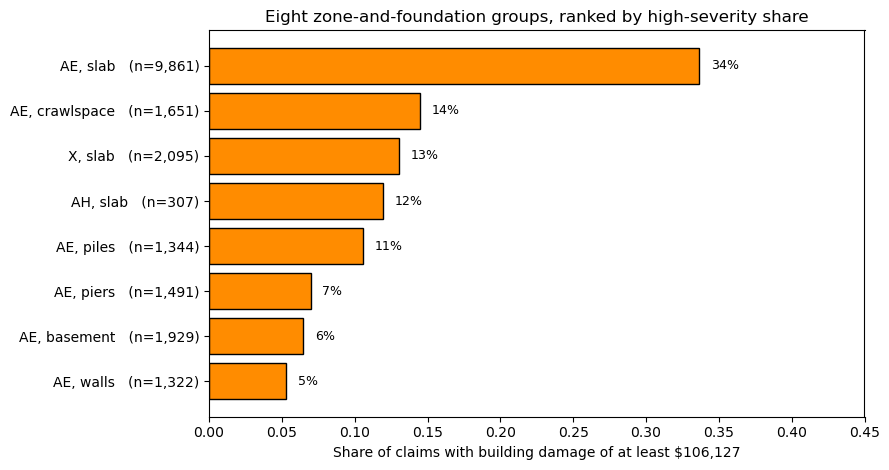

In [3]:
zone_found = pd.get_dummies(s3[['flood_zone_family', 'foundationType']], dtype=int)
Xz = StandardScaler().fit_transform(zone_found)
pair_labels = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit(Xz).labels_
s3['pair_id'] = pair_labels
print(f"Silhouette: {silhouette_score(Xz, pair_labels, sample_size=5000, random_state=SEED):.3f}")

pairs = s3.groupby('pair_id').agg(
    claims=('pair_id', 'size'),
    high_severity_share=('high_severity', 'mean'),
    median_payment_if_paid=('amountPaidOnBuildingClaim', lambda x: x[x > 0].median()),
)
pairs['flood zone'] = s3.groupby('pair_id')['flood_zone_family'].agg(lambda x: x.value_counts().index[0])
pairs['zone share'] = s3.groupby('pair_id')['flood_zone_family'].agg(lambda x: x.value_counts(normalize=True).iloc[0])
pairs['foundation'] = s3.groupby('pair_id')['foundationType'].agg(lambda x: FOUNDATION[x.value_counts().index[0]])
pairs['foundation share'] = s3.groupby('pair_id')['foundationType'].agg(lambda x: x.value_counts(normalize=True).iloc[0])
pairs = pairs.sort_values('high_severity_share', ascending=True)
pairs['label'] = pairs.apply(
    lambda r: f"{r['flood zone']}, {r['foundation']}   (n={r['claims']:,.0f})", axis=1)
print(pairs.sort_values('high_severity_share', ascending=False).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(pairs['label'], pairs['high_severity_share'], color='darkorange', edgecolor='black')
for bar, share in zip(bars, pairs['high_severity_share']):
    ax.text(share + 0.008, bar.get_y() + bar.get_height() / 2, f'{share:.0%}', va='center', fontsize=9)
ax.set_xlim(0, 0.45)
ax.set_xlabel('Share of claims with building damage of at least $106,127')
ax.set_title('Eight zone-and-foundation groups, ranked by high-severity share')
plt.tight_layout()
plt.show()


**How to read this chart.** One bar is one group. The label is the flood zone and foundation shared by that group, and **n** is how many of the 20,000 claims fell in it. A longer bar means a larger share of those claims reached the high-severity cutoff.

The top bar is half the sample. **9,861 claims are slab houses in zone AE, and 34% of them are high severity.** Median payment on the paid claims in that bar is about $85,000.

Two comparisons are sitting in the bars:

- **Same foundation, different zone.** Slab in AE is 34%. Slab in X, outside the high-risk floodplain, is 13% (2,095 claims). Slab in AH, shallow flooding, is 12%, but that bar is only 307 claims.
- **Same zone, different foundation.** Inside AE, crawlspace is 15%, piles are 11%, piers are 7%, and walls are 5%. Raising the house off the slab is the drop from the top bar to the bottom bars.

The basement bar (7%) is the least pure group: only 59% of its claims are actually in zone AE. Basement payments are also capped by NFIP coverage rules, so a short bar there is not proof that a basement is safe.

The bars separate cleanly because the input was two codes. A slab house in AE cannot land in the "X, slab" bar. This chart restates the code pairs. It does not discover a new grouping.


## 3. Mobile homes against every other claim

K-means with k = 2 on the same building features used in notebook 04: flood zone, foundation, building age, floors, occupancy, CRS class, and coverage. The silhouette is about 0.46. The small group is occupancy 14 (mobile homes), floors code 5, median coverage $70,000.

Silhouette: 0.462
        claims  high_severity_share  median_coverage  florida_share  top occupancy  occupancy share  top floors             group
two_id                                                                                                                           
0        19509                0.219         250000.0          0.585             11            0.767         1.0  All other claims
1          491                0.035          70000.0          0.723             14            0.988         5.0      Mobile homes


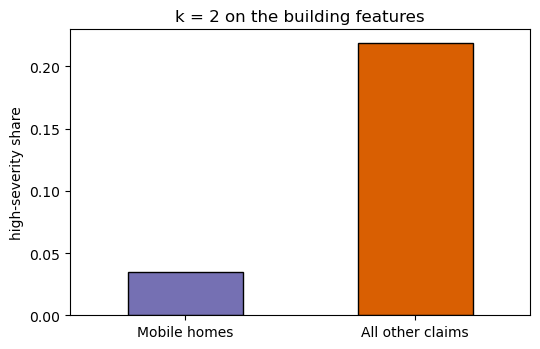

In [4]:
NOM3 = [c for c in FL['RQ3'] if c in FL['NOMINAL_FEATURES']]
X3 = pd.get_dummies(s3[FL['RQ3']], columns=NOM3, dtype=int)
X3['totalBuildingInsuranceCoverage'] = np.log1p(X3['totalBuildingInsuranceCoverage'])
X3s = StandardScaler().fit_transform(X3)
two_labels = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X3s).labels_
s3['two_id'] = two_labels
print(f"Silhouette: {silhouette_score(X3s, two_labels, sample_size=5000, random_state=SEED):.3f}")

two = s3.groupby('two_id').agg(
    claims=('two_id', 'size'),
    high_severity_share=('high_severity', 'mean'),
    median_coverage=('totalBuildingInsuranceCoverage', 'median'),
    florida_share=('state', lambda x: (x == 'FL').mean()),
)
two['top occupancy'] = s3.groupby('two_id')['occupancyType'].agg(lambda x: int(x.value_counts().index[0]))
two['occupancy share'] = s3.groupby('two_id')['occupancyType'].agg(lambda x: x.value_counts(normalize=True).iloc[0])
two['top floors'] = s3.groupby('two_id')['numberOfFloorsInTheInsuredBuilding'].agg(lambda x: x.value_counts().index[0])
two['group'] = np.where(two['top occupancy'] == 14, 'Mobile homes', 'All other claims')
s3['two_group'] = s3['two_id'].map(two['group'])
print(two.round(3).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3.6))
plot_two = two.set_index('group')['high_severity_share'].reindex(['Mobile homes', 'All other claims'])
plot_two.plot.bar(ax=ax, color=['#7570b3', '#d95f02'], edgecolor='black')
ax.set_ylabel('high-severity share')
ax.set_xlabel('')
ax.set_title('k = 2 on the building features')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. DBSCAN on the principal components

DBSCAN groups claims that have many neighbors and leaves isolated claims as noise. The radius is the distance to the 16th nearest neighbor, the same neighborhood size as lecture 10. Three radii are tried: the median, the 75th percentile, and the 90th percentile of that distance. The components come from the same building features as section 3.


PC1 8.7%, PC2 7.2%, 18 components 80.3%


        space          radius   eps  clusters  noise share  largest group  silhouette, noise dropped
 2 components          median 0.023        77        0.453           3971                      0.474
 2 components 75th percentile 0.068        80        0.184           3984                      0.264
 2 components 90th percentile 0.131        20        0.062          17168                     -0.430
18 components          median 0.187        78        0.445           3958                      0.253
18 components 75th percentile 0.487        66        0.186           5547                      0.684
18 components 90th percentile 1.175       113        0.074           5555                      0.718


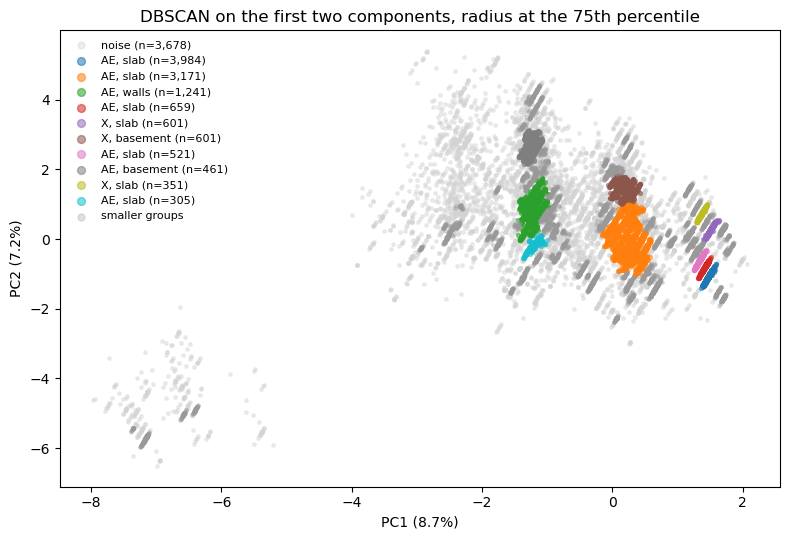

In [5]:
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

NOM3 = [c for c in FL['RQ3'] if c in FL['NOMINAL_FEATURES']]
Xpc = pd.get_dummies(s3[FL['RQ3']], columns=NOM3, dtype=int)
Xpc['totalBuildingInsuranceCoverage'] = np.log1p(Xpc['totalBuildingInsuranceCoverage'])
pca = PCA(random_state=SEED).fit(StandardScaler().fit_transform(Xpc))
Z = pca.transform(StandardScaler().fit_transform(Xpc))
print(f"PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}, "
      f"18 components {np.cumsum(pca.explained_variance_ratio_)[17]:.1%}")

def dbscan_summary(space, name):
    kd = np.sort(NearestNeighbors(n_neighbors=16).fit(space).kneighbors(space)[0][:, -1])
    rows = []
    chosen = None
    for label, q in [('median', 50), ('75th percentile', 75), ('90th percentile', 90)]:
        eps = float(np.percentile(kd, q))
        labels = DBSCAN(eps=eps, min_samples=16, n_jobs=-1).fit(space).labels_
        n_noise = int((labels == -1).sum())
        n_clusters = len(set(labels)) - (1 if n_noise else 0)
        sizes = pd.Series(labels)
        sizes = sizes[sizes >= 0].value_counts()
        kept = labels >= 0
        sil = np.nan
        if n_clusters >= 2 and sizes.min() >= 2:
            sil = silhouette_score(space[kept], labels[kept], sample_size=5000, random_state=SEED)
        rows.append({
            'space': name,
            'radius': label,
            'eps': eps,
            'clusters': n_clusters,
            'noise share': n_noise / len(labels),
            'largest group': int(sizes.iloc[0]) if len(sizes) else 0,
            'silhouette, noise dropped': sil,
        })
        if q == 75:
            chosen = labels
    return pd.DataFrame(rows), chosen

sum2, labels2 = dbscan_summary(Z[:, :2], '2 components')
sum18, labels18 = dbscan_summary(Z[:, :18], '18 components')
print(pd.concat([sum2, sum18], ignore_index=True).round(3).to_string(index=False))

# Plot the 2-component run at the middle radius. Color only groups of 300 or more.
s3['db2'] = labels2
big = s3['db2'].value_counts()
big = big[(big.index != -1) & (big >= 300)]
fig, ax = plt.subplots(figsize=(8, 5.5))
noise = s3['db2'] == -1
ax.scatter(Z[noise, 0], Z[noise, 1], s=6, c='lightgray', alpha=0.4, label=f'noise (n={(noise).sum():,})')
cmap = plt.cm.tab10.colors
for i, (cid, n) in enumerate(big.items()):
    m = s3['db2'] == cid
    sub = s3.loc[m]
    zone = sub['flood_zone_family'].value_counts().index[0]
    found = FOUNDATION[sub['foundationType'].value_counts().index[0]]
    ax.scatter(Z[m.to_numpy(), 0], Z[m.to_numpy(), 1], s=8, alpha=0.55, color=cmap[i % 10],
               label=f'{zone}, {found} (n={n:,})')
small = (~noise) & ~s3['db2'].isin(big.index)
ax.scatter(Z[small.to_numpy(), 0], Z[small.to_numpy(), 1], s=6, c='0.6', alpha=0.3, label='smaller groups')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.set_title('DBSCAN on the first two components, radius at the 75th percentile')
ax.legend(markerscale=2, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


**What DBSCAN on the components shows.** The radius decides the picture, and none of the settings is a few separated risk profiles.

On the **first two components** (16% of the variance):

- A tight radius (the median distance) makes **77 clusters** and marks **45%** of claims as noise.
- The middle radius, which is the one in the plot, makes **80 clusters** and marks **18%** of claims as noise. The silhouette on the points that were kept is **0.26**. The groups large enough to see are still slab houses, mostly in zone AE.
- A wide radius (the 90th percentile) collapses **17,168 of 20,000** claims into one group, and the silhouette turns negative.

On **18 components** (80% of the variance), the middle radius makes **66 clusters** and leaves **19%** as noise. The silhouette on the kept points is **0.68**, which looks strong only because each cluster is one pure code: AE slab and single-family is 5,547 claims, zone X slab is 1,245, AE piers is 465, AE basement is 419. The same shredding showed up when DBSCAN was run on the original columns.

So DBSCAN on the principal components either piles almost every claim into one cloud or cuts the zone-and-foundation codes into many small groups. It does not find a new set of profiles.


## 4.1 Three components

The first three components together hold 22% of the variance. PC3 is mostly zone AE against zone X. K-means and DBSCAN below use only those three columns. "Silhouette on the original columns" scores the same labels back on all 31 building columns, so a group that exists only inside the 22% does not get credit.


In [6]:
Z3 = Z[:, :3]
print(f"PC3 {pca.explained_variance_ratio_[2]:.1%}, three components together {pca.explained_variance_ratio_[:3].sum():.1%}")

rows = []
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z3).labels_
    counts = pd.Series(labels).value_counts()
    rows.append({
        'k': k,
        'silhouette in 3 components': silhouette_score(Z3, labels, sample_size=5000, random_state=SEED),
        'silhouette on the original columns': silhouette_score(
            StandardScaler().fit_transform(Xpc), labels, sample_size=5000, random_state=SEED),
        'largest group': int(counts.max()),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

kd = np.sort(NearestNeighbors(n_neighbors=16).fit(Z3).kneighbors(Z3)[0][:, -1])
print()
for name, q in [('median', 50), ('75th percentile', 75), ('90th percentile', 90)]:
    eps = float(np.percentile(kd, q))
    labels = DBSCAN(eps=eps, min_samples=16, n_jobs=-1).fit(Z3).labels_
    n_noise = int((labels == -1).sum())
    n_clusters = len(set(labels)) - (1 if n_noise else 0)
    sizes = pd.Series(labels)
    sizes = sizes[sizes >= 0].value_counts()
    kept = labels >= 0
    sil = silhouette_score(Z3[kept], labels[kept], sample_size=5000, random_state=SEED)
    print(f"DBSCAN {name:16} clusters {n_clusters:3d}   noise {n_noise / len(labels):5.1%}   "
          f"largest {int(sizes.iloc[0]):5d}   silhouette {sil:.3f}")


PC3 6.4%, three components together 22.3%


 k  silhouette in 3 components  silhouette on the original columns  largest group
 2                       0.707                               0.462          19509
 3                       0.400                               0.174          11412
 4                       0.458                               0.156           8599
 5                       0.468                               0.161           8346
 6                       0.459                               0.125           6409
 7                       0.466                               0.133           6400
 8                       0.471                               0.136           6398



DBSCAN median           clusters  76   noise 44.7%   largest  3957   silhouette 0.526


DBSCAN 75th percentile  clusters  55   noise 18.9%   largest  5550   silhouette 0.550


DBSCAN 90th percentile  clusters  36   noise  5.5%   largest  5646   silhouette 0.200


**Three components do not add a new set of profiles.** K-means at k = 2 scores 0.71 inside the three components and 0.46 on the original columns. That split is the same 491 mobile homes (median coverage $70,000) against the other 19,509 claims. From k = 3 to k = 8 the silhouette inside the three components stays near 0.45, but on the original columns it falls to about 0.13–0.17. The groups look separated only because 78% of the variation was left out.

DBSCAN on the three components repeats the earlier pattern. A tight radius makes 76 clusters and marks 45% of claims as noise. The middle radius makes 55 clusters. A wide radius leaves the largest group at about 5,600 claims and the silhouette falls to 0.20. The third component, which mostly contrasts zone AE with zone X, does not pull those zones into separate clouds.


## What these three pictures are

The map separates coasts. Florida's high-severity share is about 31%, and the other three regions are about 8–11%. The zone-and-foundation bars separate building codes: AE slab is the high group, and basement and elevated foundations are the low groups. The two-group fit separates mobile homes, whose median coverage is $70,000, from everyone else.

None of the three is a profile built from flood zone, elevation, and construction at once. Those features together stay overlapped, which is the result in `05_rq3_check.ipynb`.